# HepatoClust

## Retrouver les maladies du foie à partir d'analyses de sang, sans étiquettes

**Module** Machine Learning 2, Pr. Safaâ Dafrallah
**École** ENSAM Rabat, INDIA S3
**Groupe** KONKOBO Windpouyire Faissal Cedric

### Le projet en bref

Nous utilisons le jeu de données HCV de l'UCI. Il contient les analyses de sang de 615 personnes : des donneurs de sang et des patients atteints d'une maladie du foie (hépatite, fibrose, cirrhose).

Notre question est simple : à partir des analyses de sang seules, peut-on former des groupes de personnes qui se ressemblent, et ces groupes séparent-ils les personnes saines des personnes malades ?

Pour y répondre, nous appliquons plusieurs méthodes de clustering vues en cours (K-Means, classification hiérarchique, DBSCAN), puis nous les comparons et analysons les groupes obtenus.

**Règle importante** : la colonne qui indique la vraie catégorie de chaque personne n'est jamais utilisée pour construire les groupes. Elle sert seulement à la fin, pour vérifier les résultats.

## Table des matières

0. [Import des packages](#partie0)
1. [Exploration des données](#partie1)
2. [Préparation des données](#partie2)
3. [K-Means](#partie3)
4. [Classification hiérarchique (CAH)](#partie4)
5. [Bonus : DBSCAN](#partie5)
6. [Évaluation et comparaison des méthodes](#partie6)
7. [Analyse des groupes et conclusion](#partie7)

<a id="partie0"></a>
## Partie 0 : Import des packages

Nous chargeons les bibliothèques utilisées dans tout le projet :

- **pandas** et **numpy** pour manipuler les données
- **matplotlib** pour les graphiques
- **scikit-learn** pour la préparation des données, K-Means, DBSCAN et les mesures d'évaluation
- **scipy** pour la classification hiérarchique, les dendrogrammes et le CPCC

In [1]:
# Outils de base
import os
import time
import warnings

# Manipulation des données
import numpy as np
import pandas as pd

# Graphiques
import matplotlib.pyplot as plt

# Préparation des données
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Algorithmes de clustering
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors

#ACP
from sklearn.decomposition import PCA

# Mesures d'évaluation
from sklearn.metrics import silhouette_score, silhouette_samples

# Classification hiérarchique (CAH)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist, squareform

In [2]:
# Graine aléatoire fixée pour obtenir les mêmes résultats à chaque exécution
SEED = 42
np.random.seed(SEED)

# Affichage des tableaux pandas : toutes les colonnes, 2 décimales
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

# Style des graphiques
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Masquer les avertissements sans importance
warnings.filterwarnings("ignore")

# Dossier où seront enregistrées les figures pour les diapositives
os.makedirs("figures", exist_ok=True)

print("Packages chargés, tout est prêt.")

Packages chargés, tout est prêt.


<a id="partie1"></a>
## Partie 1 : Exploration des données

Avant d'appliquer un algorithme, nous regardons les données : leur taille, les catégories de personnes, les valeurs manquantes et la forme des analyses de sang.

### 1.1 Chargement du fichier

Nous lisons le fichier CSV et affichons les premières lignes.

In [3]:
df = pd.read_csv("hcvdat0.csv", index_col=0)
df.head()

,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
1,0=Blood Donor,32,m,38.50,52.50,7.70,22.10,7.50,6.93,3.23,106.00,12.10,69.00
2,0=Blood Donor,32,m,38.50,70.30,18.00,24.70,3.90,11.17,4.80,74.00,15.60,76.50
3,0=Blood Donor,32,m,46.90,74.70,36.20,52.60,6.10,8.84,5.20,86.00,33.20,79.30
4,0=Blood Donor,32,m,43.20,52.00,30.60,22.60,18.90,7.33,4.74,80.00,33.80,75.70
5,0=Blood Donor,32,m,39.20,74.10,32.60,24.80,9.60,9.15,4.32,76.00,29.90,68.70


In [4]:
df.tail()

,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
611,3=Cirrhosis,62,f,32.00,416.60,5.90,110.30,50.00,5.57,6.30,55.70,650.90,68.50
612,3=Cirrhosis,64,f,24.00,102.80,2.90,44.40,20.00,1.54,3.02,63.00,35.90,71.30
613,3=Cirrhosis,64,f,29.00,87.30,3.50,99.00,48.00,1.66,3.63,66.70,64.20,82.00
614,3=Cirrhosis,46,f,33.00,NaN,39.00,62.00,20.00,3.56,4.20,52.00,50.00,71.00
615,3=Cirrhosis,59,f,36.00,NaN,100.00,80.00,12.00,9.07,5.30,67.00,34.00,68.00


### 1.2 Taille et types des colonnes

In [5]:
df.shape

(615, 13)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 615 entries, 1 to 615
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Category  615 non-null    str    
 1   Age       615 non-null    int64  
 2   Sex       615 non-null    str    
 3   ALB       614 non-null    float64
 4   ALP       597 non-null    float64
 5   ALT       614 non-null    float64
 6   AST       615 non-null    float64
 7   BIL       615 non-null    float64
 8   CHE       615 non-null    float64
 9   CHOL      605 non-null    float64
 10  CREA      615 non-null    float64
 11  GGT       615 non-null    float64
 12  PROT      614 non-null    float64
dtypes: float64(10), int64(1), str(2)
memory usage: 62.6 KB


### 1.3 Les catégories réelles.

In [7]:
df["Category"].value_counts()

Category
0=Blood Donor             533
3=Cirrhosis                30
1=Hepatitis                24
2=Fibrosis                 21
0s=suspect Blood Donor      7
Name: count, dtype: int64

In [8]:
# La même chose en pourcentage
df["Category"].value_counts(normalize=True).mul(100).round(1)


Category
0=Blood Donor            86.70
3=Cirrhosis               4.90
1=Hepatitis               3.90
2=Fibrosis                3.40
0s=suspect Blood Donor    1.10
Name: proportion, dtype: float64

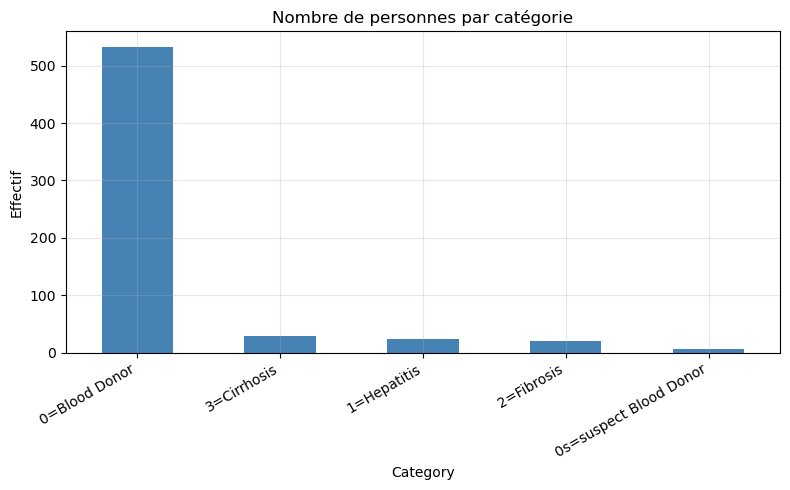

In [16]:
# Diagramme en barres des effectifs
df["Category"].value_counts().plot(kind="bar", color="steelblue")
plt.title("Nombre de personnes par catégorie")
plt.ylabel("Effectif")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("figures/1_categories.png", dpi=150)
plt.show()

### 1.4 Les valeurs manquantes 

In [9]:
df.isna().sum()

Category     0
Age          0
Sex          0
ALB          1
ALP         18
ALT          1
AST          0
BIL          0
CHE          0
CHOL        10
CREA         0
GGT          0
PROT         1
dtype: int64

In [11]:
# Nombre de personnes qui ont au moins une valeur manquante
print(df.isna().any(axis=1).sum())

26


### 1.4 Les échelles des analyses

In [12]:
analyses = ["ALB", "ALP", "ALT", "AST", "BIL", "CHE", "CHOL", "CREA", "GGT", "PROT"]
df[analyses].describe()

,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
count,614.00,597.00,614.00,615.00,615.00,615.00,605.00,615.00,615.00,614.00
mean,41.62,68.28,28.45,34.79,11.40,8.20,5.37,81.29,39.53,72.04
std,5.78,26.03,25.47,33.09,19.67,2.21,1.13,49.76,54.66,5.40
min,14.90,11.30,0.90,10.60,0.80,1.42,1.43,8.00,4.50,44.80
25%,38.80,52.50,16.40,21.60,5.30,6.94,4.61,67.00,15.70,69.30
50%,41.95,66.20,23.00,25.90,7.30,8.26,5.30,77.00,23.30,72.20
75%,45.20,80.10,33.08,32.90,11.20,9.59,6.06,88.00,40.20,75.40
max,82.20,416.60,325.30,324.00,254.00,16.41,9.67,1079.10,650.90,90.00


### 1.5 La distribution des analyses

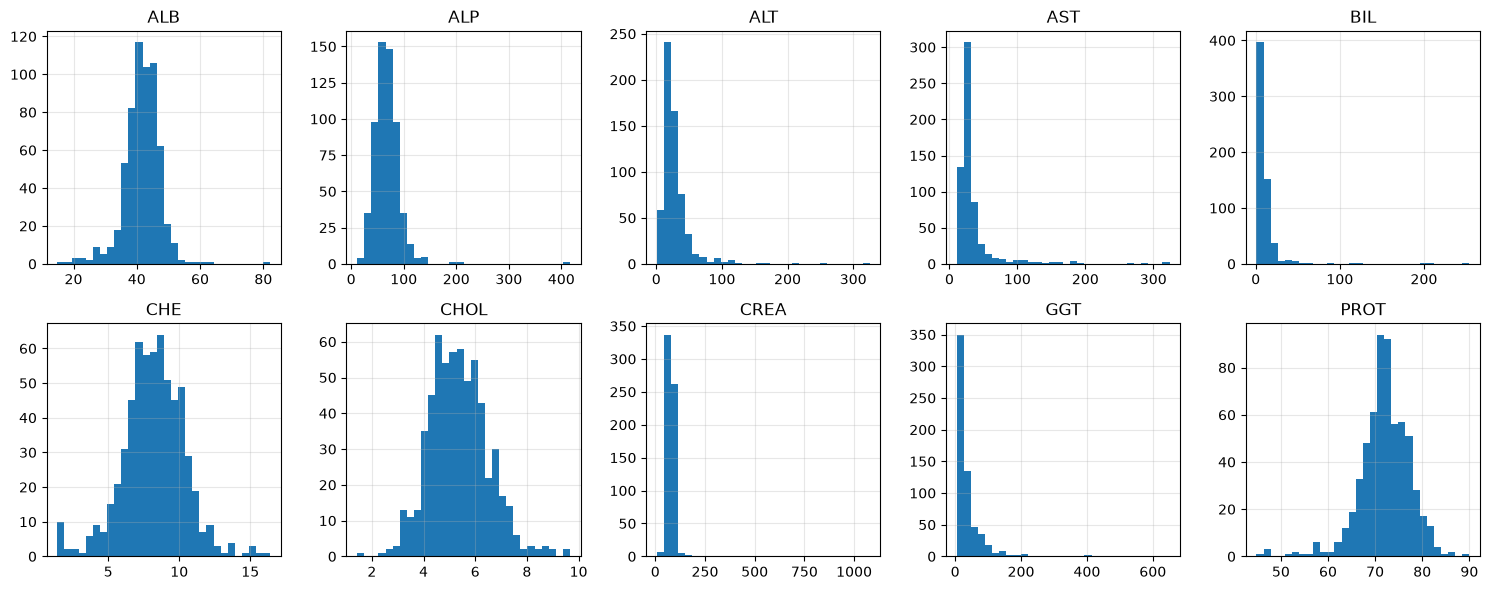

In [13]:
df[analyses].hist(bins=30, figsize=(15, 6), layout=(2, 5))
plt.tight_layout()
plt.savefig("figures/1_histogrammes.png", dpi=150)
plt.show()

### Bilan de l'exploration

- 615 personnes, 10 analyses de sang utilisées pour le clustering.
- Groupes très déséquilibrés : 533 donneurs (86,7 %) contre 75 malades. Il faudra surveiller la taille des clusters.
- 31 valeurs manquantes, surtout ALP (18) et CHOL (10) : remplacement par la médiane pour garder tous les malades.
- Échelles très différentes (CREA jusqu'à 1000, CHOL entre 2 et 10) : standardisation obligatoire.
- ALT, AST, BIL, GGT, CREA et ALP sont très asymétriques, avec des valeurs extrêmes : transformation log avant la standardisation.

<a id="partie2"></a>
## Partie 2 : Préparation des données

Nous appliquons les décisions prises après l'exploration : garder les 10 analyses, remplacer les valeurs manquantes, réduire l'asymétrie, puis standardiser.

### 2.1 Séparer les analyses et la catégorie

In [14]:
X = df[analyses].copy()
y = df["Category"]
X.shape

(615, 10)

### 2.2 Remplacer les valeurs manquantes

In [15]:
X = X.fillna(X.median())
X.isna().sum().sum()

np.int64(0)

Il n'y a plus aucune valeur manquante

### 2.3 Réduire l'asymétrie avec le log

In [17]:
asymetriques = ["ALP", "ALT", "AST", "BIL", "CREA", "GGT"]

X_log = X.copy()
X_log[asymetriques] = np.log1p(X_log[asymetriques])

pd.DataFrame({"avant": X[asymetriques].skew(),
              "après": X_log[asymetriques].skew()}).round(2)

,avant,après
ALP,4.73,-0.19
ALT,5.51,-0.08
AST,4.94,1.96
BIL,8.39,1.48
CREA,15.17,0.87
GGT,5.63,1.03


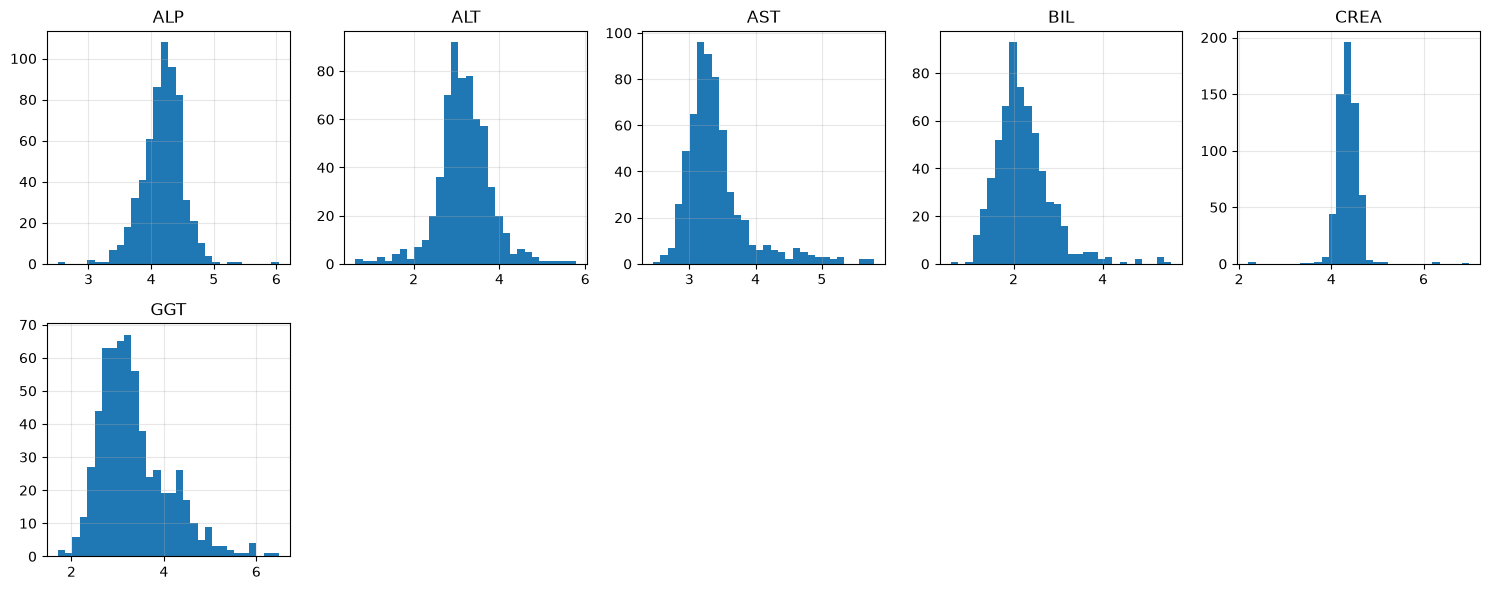

In [18]:
X_log[asymetriques].hist(bins=30, figsize=(15, 6), layout=(2, 5))
plt.tight_layout()
#plt.savefig("figures/1_histogrammes.png", dpi=150)
plt.show()

### 2.4 Standardiser

In [19]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_log), columns=analyses, index=X.index)
X_scaled.describe().loc[["mean", "std"]].round(2)

,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
mean,0.00,-0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


### 2.5 Avant et après la préparation

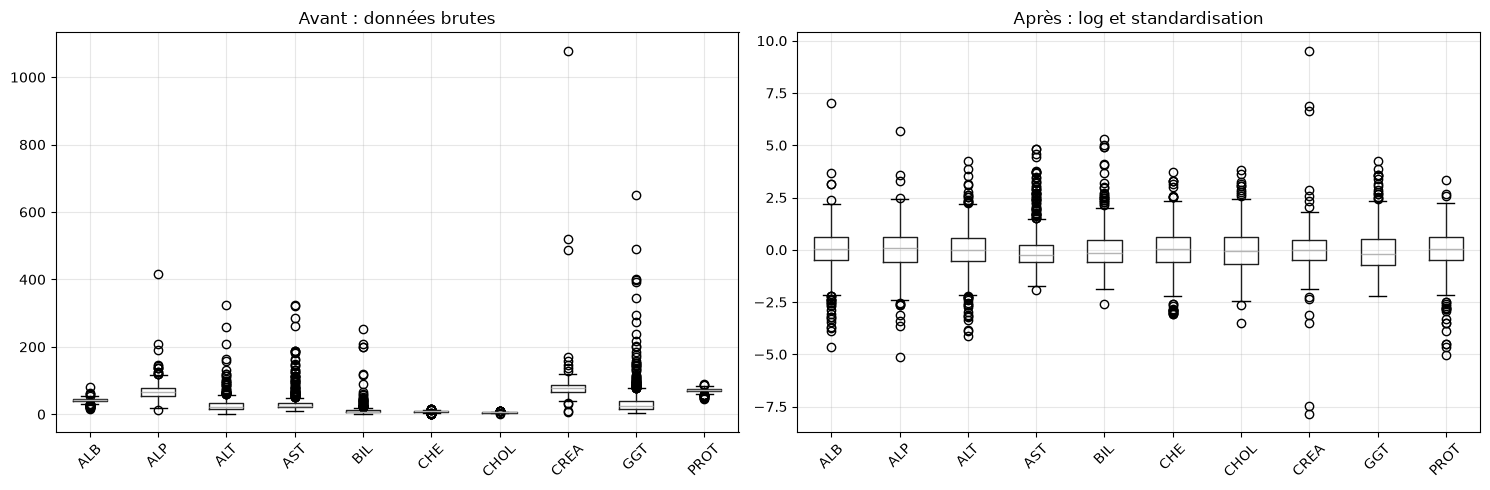

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

X.boxplot(ax=axes[0], rot=45)
axes[0].set_title("Avant : données brutes")

X_scaled.boxplot(ax=axes[1], rot=45)
axes[1].set_title("Après : log et standardisation")

plt.tight_layout()
plt.savefig("figures/2_avant_apres.png", dpi=150)
plt.show()

### Bilan de la préparation

- 615 personnes, 10 analyses, plus aucune valeur manquante.
- Asymétrie réduite par le log sur ALP, ALT, AST, BIL, CREA et GGT.
- Toutes les analyses standardisées : même poids dans les distances.

X_scaled est la matrice utilisée par tous les algorithmes de clustering. Nous utilisons la distance euclidienne, qui a du sens maintenant que les variables sont sur la même échelle.

<a id="partie3"></a>
## Partie 3 : K-Means

Nous cherchons le bon nombre de groupes K, nous construisons le modèle final, puis nous montrons que le résultat dépend de l'initialisation.

K-Means place K centres, affecte chaque personne au centre le plus proche, puis recalcule les centres, et recommence jusqu'à stabilité (heuristique de Lloyd). Le résultat dépend des centres de départ : on peut tomber sur un minimum local.

### 3.1 Tester K de 2 à 8

K n'est pas connu à l'avance. Pour chaque K, nous calculons l'inertie (méthode du coude) et la silhouette.

In [22]:
K_range = range(2, 9)
resultats_k = []

for k in K_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED)
    labels = km.fit_predict(X_scaled)
    resultats_k.append({"K": k,
                        "inertie": km.inertia_,
                        "silhouette": silhouette_score(X_scaled, labels)})

resultats_k = pd.DataFrame(resultats_k).set_index("K")
resultats_k

,inertie,silhouette
K,,
2,5285.85,0.16
3,4545.27,0.17
4,4256.04,0.15
5,3981.69,0.12
6,3723.80,0.11
7,3589.02,0.10
8,3330.49,0.11


### 3.2 Coude et silhouette

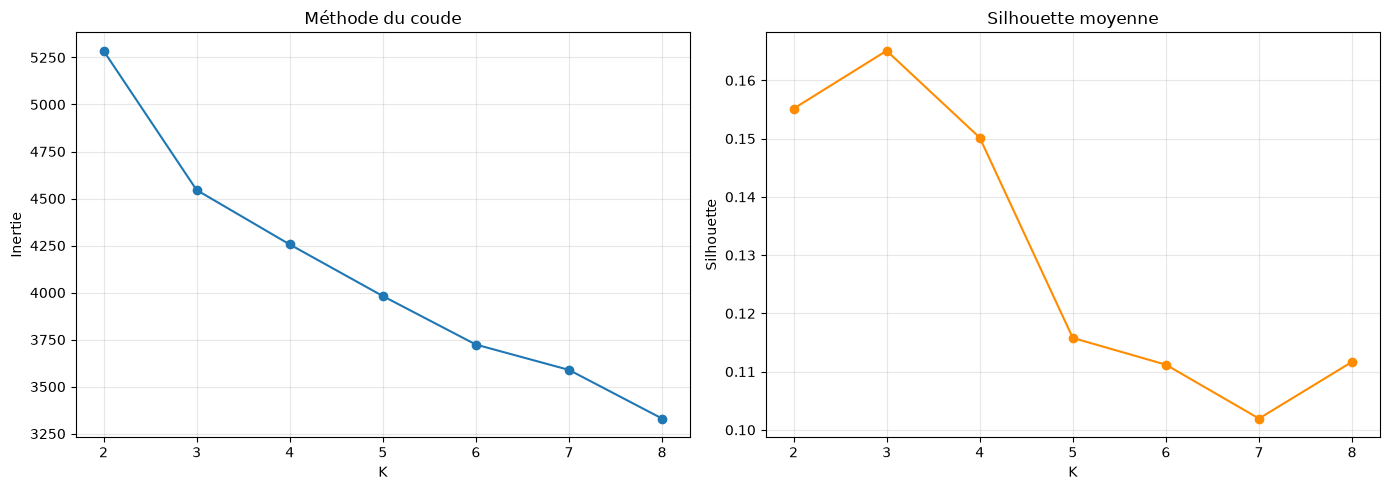

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(resultats_k.index, resultats_k["inertie"], marker="o")
axes[0].set_title("Méthode du coude")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertie")

axes[1].plot(resultats_k.index, resultats_k["silhouette"], marker="o", color="darkorange")
axes[1].set_title("Silhouette moyenne")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.savefig("figures/3_coude_silhouette.png", dpi=150)
plt.show()

### 3.3 Modèle final

In [24]:
K_choisi = 3  

debut = time.time()
kmeans = KMeans(n_clusters=K_choisi, init="k-means++", n_init=10, random_state=SEED)
labels_kmeans = kmeans.fit_predict(X_scaled)
temps_kmeans = time.time() - debut

pd.Series(labels_kmeans).value_counts()

1    322
0    262
2     31
Name: count, dtype: int64

### 3.4 Visualisation des clusters

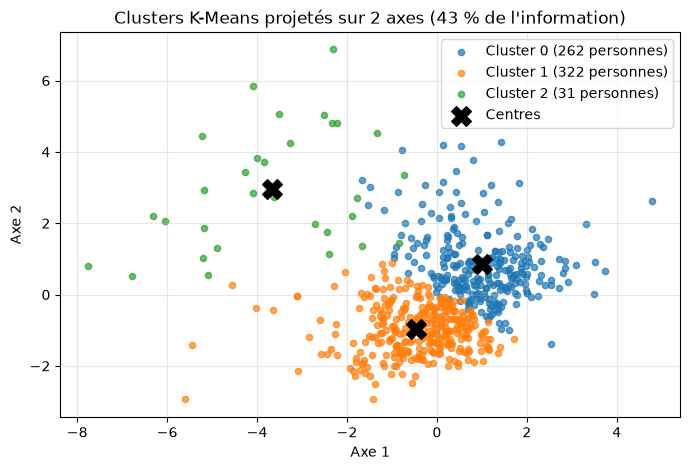

In [25]:
acp = PCA(n_components=2, random_state=SEED)
X_2d = acp.fit_transform(X_scaled)
centres_2d = acp.transform(kmeans.cluster_centers_)
part_variance = acp.explained_variance_ratio_.sum() * 100

for c in range(K_choisi):
    masque = labels_kmeans == c
    plt.scatter(X_2d[masque, 0], X_2d[masque, 1], s=20, alpha=0.7,
                label=f"Cluster {c} ({masque.sum()} personnes)")

plt.scatter(centres_2d[:, 0], centres_2d[:, 1], c="black", marker="X", s=200, label="Centres")
plt.title(f"Clusters K-Means projetés sur 2 axes ({part_variance:.0f} % de l'information)")
plt.xlabel("Axe 1")
plt.ylabel("Axe 2")
plt.legend()
plt.savefig("figures/3_clusters_kmeans.png", dpi=150)
plt.show()

### 3.4 Instabilité de l'initialisation

Avec des centres de départ au hasard et un seul essai (n_init=1), chaque graine peut donner une inertie différente : l'algorithme s'arrête dans un minimum local. C'est pour cela qu'on utilise k-means++ et plusieurs essais. Nous prenons K=4, car l'effet est plus visible avec plus de groupes.

In [26]:
essais = []
for graine in range(10):
    km = KMeans(n_clusters=4, init="random", n_init=1, random_state=graine).fit(X_scaled)
    essais.append({"graine": graine, "inertie": km.inertia_})

pd.DataFrame(essais).set_index("graine").round(1)

,inertie
graine,
0,4241.90
1,4301.00
2,4283.00
3,4289.40
4,4241.50
5,4241.90
6,4342.00
7,4258.00
8,4869.50


- Avec n_init=1, l'inertie varie de 4241,5 à 4869,5 selon la graine, et seules 3 graines sur 10 atteignent la meilleure valeur : preuve des minimums locaux.

### Bilan de K-Means

- Le coude et la silhouette indiquent tous les deux K = 3 (silhouette maximale de 0,17).
- La silhouette reste faible : les groupes existent mais se chevauchent.
- Tailles des 3 clusters : 322, 262 et 31
- Avec n_init=1, l'inertie varie de 4241.90 à 4288.00 selon la graine : preuve des minimums locaux.

<a id="sauvegarde"></a>
## Sauvegarde des résultats

Nous enregistrons les données préparées et les résultats de K-Means dans le dossier resultats/. Les notebooks suivants les rechargent, ce qui garantit que toutes les méthodes travaillent sur exactement les mêmes données.

In [35]:
import json

os.makedirs("resultats", exist_ok=True)

parametres = {"SEED": SEED,
              "K_choisi": K_choisi,
              "analyses": analyses,
              "asymetriques": asymetriques}

with open("resultats/parametres.json", "w", encoding="utf-8") as f:
    json.dump(parametres, f, indent=4, ensure_ascii=False)

In [ ]:
## Données
 #données préparées (médiane, log, standardisation)
X_scaled.to_csv("resultats/X_scaled.csv")

# analyses en unités réelles, sans valeurs manquantes
X.to_csv("resultats/X_brut.csv")

# vraie catégorie
y.to_csv("resultats/categories.csv")

In [37]:
## Clusters K-Means

# cluster de chaque personne, 
labels = pd.DataFrame({"kmeans": labels_kmeans}, index=X_scaled.index)
labels.to_csv("resultats/labels.csv")
labels.head()

,kmeans
1,1
2,1
3,0
4,0
5,1


In [49]:
!python.exe -m pip install -q --upgrade pip

In [50]:
!pip install -q jqmcvi

ERROR: Could not find a version that satisfies the requirement jqmcvi (from versions: none)
ERROR: No matching distribution found for jqmcvi


In [51]:
from scipy.spatial.distance import pdist, cdist
import numpy as np

def dunn_index(X, labels):
    clusters = np.unique(labels)

    max_intra = 0
    for c in clusters:
        cluster_points = X[labels == c]

        if len(cluster_points) > 1:
            intra = np.max(pdist(cluster_points))
            max_intra = max(max_intra, intra)

    min_inter = np.inf
    for i in range(len(clusters)):
        for j in range(i + 1, len(clusters)):
            c1 = X[labels == clusters[i]]
            c2 = X[labels == clusters[j]]

            inter = np.min(cdist(c1, c2))
            min_inter = min(min_inter, inter)

    return min_inter / max_intra

In [52]:
dunn_score = dunn_index(
    X_scaled.values,
    labels_kmeans
)

In [53]:
## Metriques K-means

metriques = pd.DataFrame([{"methode": "K-Means",
                           "K": K_choisi,
                           "inertie": kmeans.inertia_,
                           "silhouette": silhouette_score(X_scaled, labels_kmeans),
                           "dunn":dunn_score,
                           "temps_s": temps_kmeans}]).set_index("methode")

metriques.to_csv("resultats/metriques.csv")
metriques

,K,inertie,silhouette,dunn,temps_s
methode,,,,,
K-Means,3,4545.27,0.17,0.06,0.12


In [54]:
sorted(os.listdir("resultats"))

['X_brut.csv',
 'X_scaled.csv',
 'categories.csv',
 'labels.csv',
 'metriques.csv',
 'parametres.json']